# Dataset Loading

Loading dataset from /kaggle/input/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz...
Keys in the dataset: ['metadata', 'imgs', 'latents_classes', 'latents_values']

Sampling and showing random images...


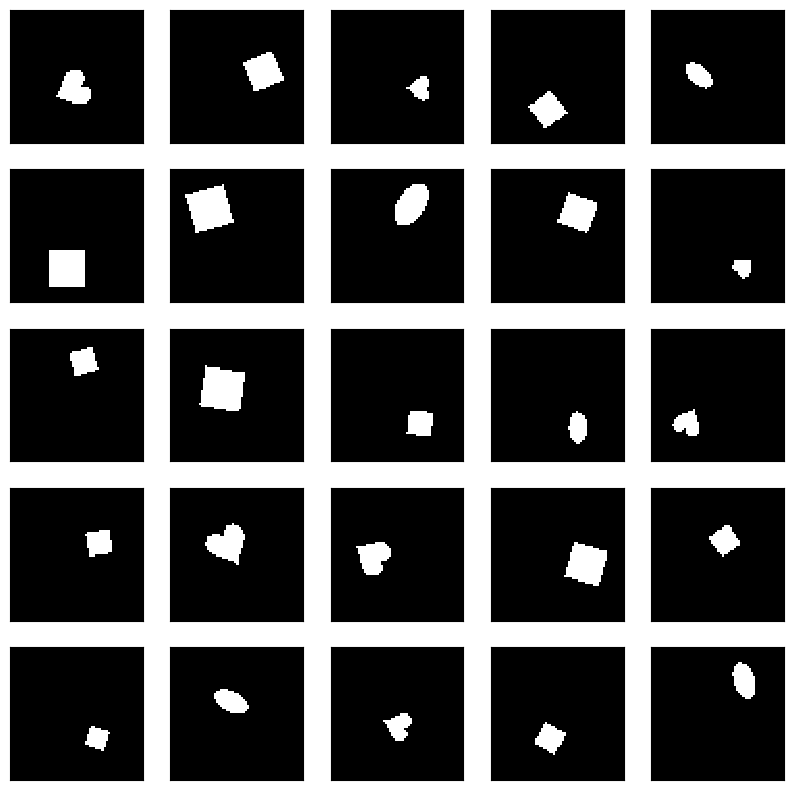

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATASET_PATH=Path("/kaggle/input/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz")

print(f"Loading dataset from {DATASET_PATH}...")
dataset_zip=np.load(DATASET_PATH,allow_pickle=True,encoding='latin1')

print('Keys in the dataset:',list(dataset_zip.keys()))
imgs=dataset_zip['imgs']
latents_values=dataset_zip['latents_values']
metadata=dataset_zip['metadata'][()]

latents_sizes=metadata['latents_sizes']
latents_bases=np.concatenate((latents_sizes[::-1].cumprod()[::-1][1:],
                                np.array([1,])))

def latent_to_index(latents):
  return np.dot(latents,latents_bases).astype(int)

def sample_latent(size=1):
  samples=np.zeros((size,latents_sizes.size))
  for lat_i,lat_size in enumerate(latents_sizes):
    samples[:,lat_i]=np.random.randint(lat_size,size=size)
  return samples

def show_images_grid(imgs_,num_images=25):
  ncols=int(np.ceil(num_images**0.5))
  nrows=int(np.ceil(num_images/ncols))
  _, axes=plt.subplots(nrows,ncols,figsize=(nrows*2,ncols*2))
  axes=axes.flatten()

  for ax_i, ax in enumerate(axes):
    if ax_i < num_images:
      ax.imshow(imgs_[ax_i],cmap='gray',interpolation='nearest')
      ax.set_xticks([])
      ax.set_yticks([])
    else:
      ax.axis('off')
  plt.show()

print("\nSampling and showing random images...")

latents_sampled=sample_latent(size=25)

indices_sampled=latent_to_index(latents_sampled)
imgs_sampled=imgs[indices_sampled]

show_images_grid(imgs_sampled,25)

# VAE training

Starting training on cuda with H_DIM = 6...


Training Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 2/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 3/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 4/50:   0%|          | 0/5760 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch 48/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 49/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 50/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Training finished.


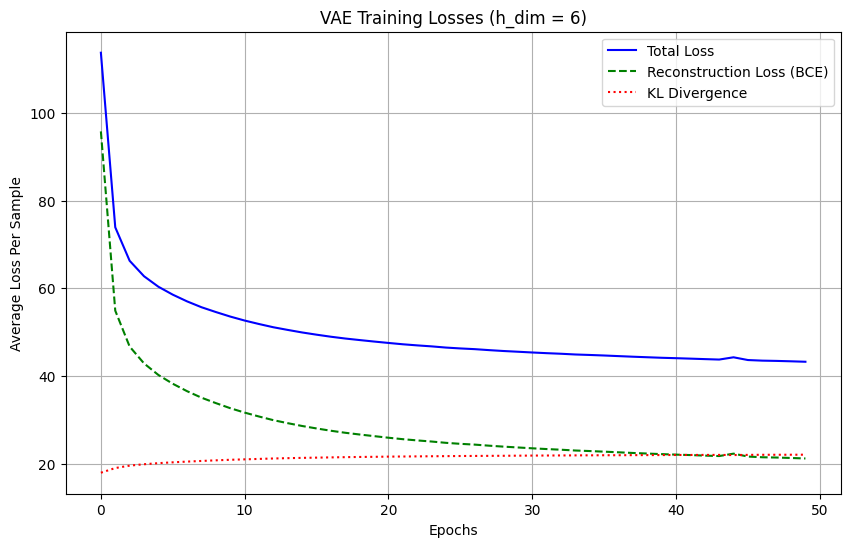

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from pathlib import Path
from tqdm.auto import tqdm

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS=50
LR=0.001
BATCH_SIZE=128
H_DIM=6 
IMG_DIM=(64,64)

class DspritesDataset(Dataset):
    def __init__(self,path):
        dataset=np.load(path,allow_pickle=True, encoding='latin1')
        self.imgs=torch.from_numpy(dataset['imgs']).float()
        
    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        return self.imgs[idx].unsqueeze(0)


class VAE(nn.Module):
    def __init__(self, h_dim=6):
        super(VAE, self).__init__()

        self.enc_conv1=nn.Conv2d(1,32,kernel_size=4,stride=2,padding=1) 
        self.enc_conv2=nn.Conv2d(32,64,kernel_size=4,stride=2,padding=1) 
        self.enc_conv3=nn.Conv2d(64,128,kernel_size=4,stride=2,padding=1)
        self.flatten=nn.Flatten()
        
        self.fc_mu=nn.Linear(8192,h_dim)
        self.fc_log_var=nn.Linear(8192,h_dim)
        
        self.dec_fc=nn.Linear(h_dim,8192)
        
        self.dec_convT1=nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1) 
        self.dec_convT2=nn.ConvTranspose2d(64,32,kernel_size=4,stride=2,padding=1) 
        self.dec_convT3=nn.ConvTranspose2d(32,1,kernel_size=4,stride=2,padding=1) 
        self.sigmoid=nn.Sigmoid()

    def encode(self,x):
        h=F.relu(self.enc_conv1(x))
        h=F.relu(self.enc_conv2(h))
        h=F.relu(self.enc_conv3(h))
        h=self.flatten(h)
        mu=self.fc_mu(h)
        log_var=self.fc_log_var(h)
        return mu,log_var

    def reparameterize(self, mu, log_var):
        std=torch.exp(0.5*log_var)
        eps=torch.randn_like(std)
        return mu+eps*std

    def decode(self,z):
        h=F.relu(self.dec_fc(z))
        h=h.view(-1,128,8,8) 
        h=F.relu(self.dec_convT1(h))
        h=F.relu(self.dec_convT2(h))
        x_recon=self.dec_convT3(h) 
        return self.sigmoid(x_recon)

    def forward(self,x):
        mu,log_var=self.encode(x)
        z=self.reparameterize(mu,log_var)
        recon_x=self.decode(z)
        return recon_x,mu,log_var

def vae_loss(recon_x,x,mu,log_var):

    BCE=F.binary_cross_entropy(recon_x,x,reduction='sum')
    
    KLD= -0.5*torch.sum(1+log_var-mu.pow(2)-log_var.exp())
    
    return BCE+KLD,BCE,KLD

dataset=DspritesDataset(DATASET_PATH)
loader=DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=True)
model=VAE(h_dim=H_DIM).to(DEVICE)
optimizer=Adam(model.parameters(),lr=LR)

print(f"Starting training on {DEVICE} with H_DIM = {H_DIM}...")

all_total_losses=[]
all_bce_losses=[]
all_kld_losses=[]

model.train()

epoch_pbar=tqdm(range(EPOCHS),desc="Training Epochs")

for epoch in epoch_pbar:
    epoch_total_loss=0
    epoch_bce_loss=0
    epoch_kld_loss=0
    
    batch_pbar=tqdm(loader,desc=f"Epoch {epoch+1}/{EPOCHS}",leave=False)
    
    for batch_idx,data in enumerate(batch_pbar):
        data=data.to(DEVICE)
        
        recon_batch,mu,log_var=model(data)
        loss,bce,kld=vae_loss(recon_batch,data,mu,log_var)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_total_loss+=loss.item()
        epoch_bce_loss+=bce.item()
        epoch_kld_loss+=kld.item()
        
    avg_total=epoch_total_loss/len(dataset)
    avg_bce=epoch_bce_loss/len(dataset)
    avg_kld=epoch_kld_loss/len(dataset)
    
    all_total_losses.append(avg_total)
    all_bce_losses.append(avg_bce)
    all_kld_losses.append(avg_kld)
    
    epoch_pbar.set_postfix(TotalLoss=f"{avg_total:.4f}",BCE=f"{avg_bce:.4f}",KLD=f"{avg_kld:.4f}")

print("Training finished.")


plt.figure(figsize=(10,6))
plt.plot(all_total_losses,label='Total Loss',color='blue')
plt.plot(all_bce_losses,label='Reconstruction Loss (BCE)',color='green',linestyle='--')
plt.plot(all_kld_losses,label='KL Divergence',color='red',linestyle=':')
plt.xlabel('Epochs')
plt.ylabel('Average Loss Per Sample')
plt.title(f'VAE Training Losses (h_dim = {H_DIM})')
plt.legend()
plt.grid(True)
plt.show()

Visualizing 8 random reconstructions...


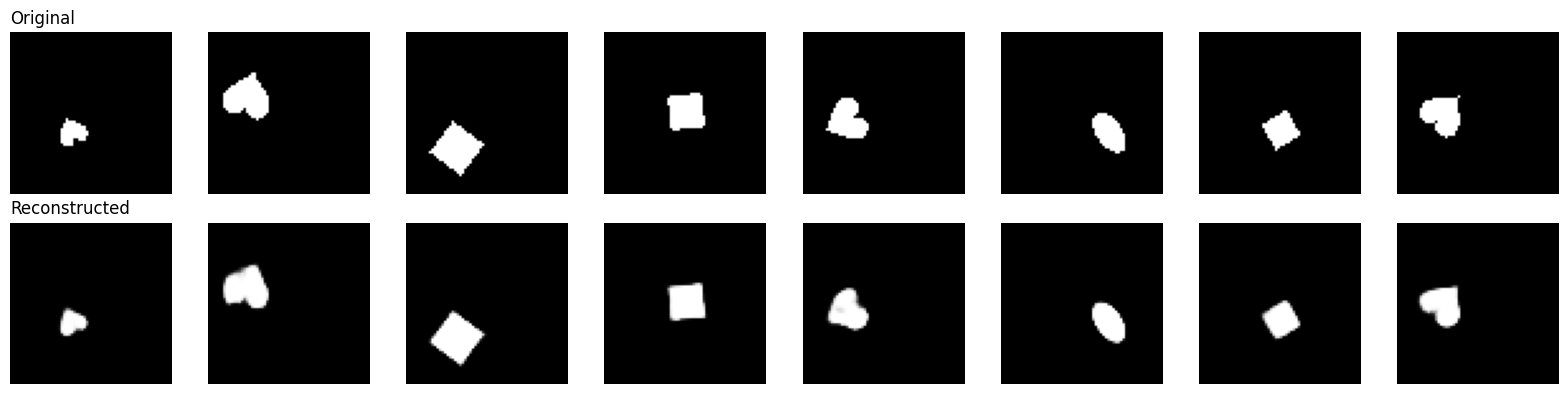

In [4]:

print("Visualizing 8 random reconstructions...")

model.eval()

num_samples=8
indices=torch.randint(0,len(dataset),(num_samples,))
samples=torch.stack([dataset[i] for i in indices]).to(DEVICE)

with torch.no_grad():
    recon_samples,_,_=model(samples)

samples_np=samples.cpu().numpy()
recon_samples_np=recon_samples.cpu().numpy()

plt.figure(figsize=(16,4))
for i in range(num_samples):
    ax=plt.subplot(2,num_samples,i +1)
    plt.imshow(samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title("Original",loc='left',fontsize=12)
        
    ax=plt.subplot(2,num_samples,i+1+num_samples)
    plt.imshow(recon_samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title("Reconstructed",loc='left',fontsize=12)

plt.tight_layout()
plt.show()

# $\beta$VAE

Starting training on cuda with H_DIM = 6...


Training Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 2/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 3/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 4/50:   0%|          | 0/5760 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch 48/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 49/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 50/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Training finished.


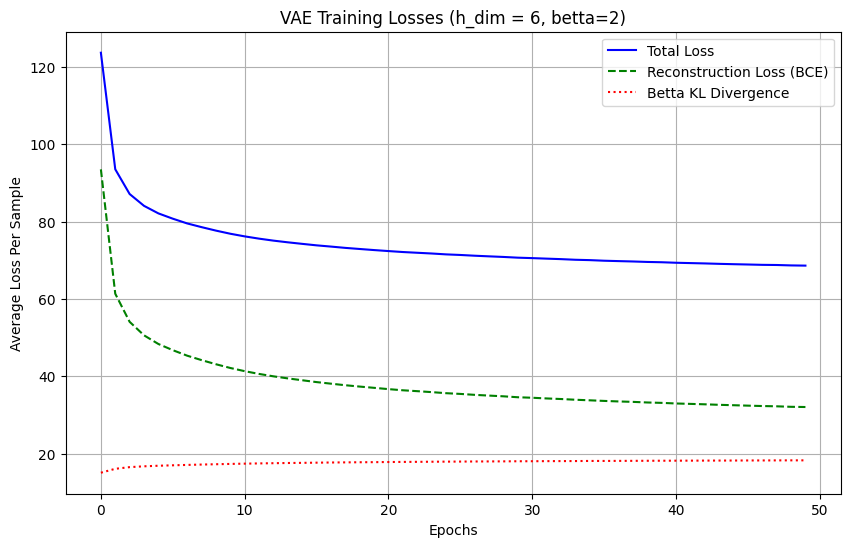

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from pathlib import Path

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS=50
LR=0.001
BATCH_SIZE=128
H_DIM=6 
IMG_DIM=(64,64)
b=2

class DspritesDataset(Dataset):
    def __init__(self,path):
        dataset=np.load(path,allow_pickle=True, encoding='latin1')
        self.imgs=torch.from_numpy(dataset['imgs']).float()
        
    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        return self.imgs[idx].unsqueeze(0)


class VAE(nn.Module):
    def __init__(self, h_dim=6):
        super(VAE, self).__init__()

        self.enc_conv1=nn.Conv2d(1,32,kernel_size=4,stride=2,padding=1) 
        self.enc_conv2=nn.Conv2d(32,64,kernel_size=4,stride=2,padding=1) 
        self.enc_conv3=nn.Conv2d(64,128,kernel_size=4,stride=2,padding=1)
        self.flatten=nn.Flatten()
        
        self.fc_mu=nn.Linear(8192,h_dim)
        self.fc_log_var=nn.Linear(8192,h_dim)
        
        self.dec_fc=nn.Linear(h_dim,8192)
        
        self.dec_convT1=nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1) 
        self.dec_convT2=nn.ConvTranspose2d(64,32,kernel_size=4,stride=2,padding=1) 
        self.dec_convT3=nn.ConvTranspose2d(32,1,kernel_size=4,stride=2,padding=1) 
        self.sigmoid=nn.Sigmoid()

    def encode(self,x):
        h=F.relu(self.enc_conv1(x))
        h=F.relu(self.enc_conv2(h))
        h=F.relu(self.enc_conv3(h))
        h=self.flatten(h)
        mu=self.fc_mu(h)
        log_var=self.fc_log_var(h)
        return mu,log_var

    def reparameterize(self, mu, log_var):
        std=torch.exp(0.5*log_var)
        eps=torch.randn_like(std)
        return mu+eps*std

    def decode(self,z):
        h=F.relu(self.dec_fc(z))
        h=h.view(-1,128,8,8) 
        h=F.relu(self.dec_convT1(h))
        h=F.relu(self.dec_convT2(h))
        x_recon=self.dec_convT3(h) 
        return self.sigmoid(x_recon)

    def forward(self,x):
        mu,log_var=self.encode(x)
        z=self.reparameterize(mu,log_var)
        recon_x=self.decode(z)
        return recon_x,mu,log_var

def vae_loss(recon_x,x,mu,log_var,b):

    BCE=F.binary_cross_entropy(recon_x,x,reduction='sum')
    
    KLD=-0.5*torch.sum(1+log_var-mu.pow(2)-log_var.exp())
    
    return BCE+b*KLD,BCE,KLD


model1_b=VAE(h_dim=H_DIM).to(DEVICE)
optimizer=Adam(model1_b.parameters(),lr=LR)

print(f"Starting training on {DEVICE} with H_DIM = {H_DIM}...")

all_total_losses=[]
all_bce_losses=[]
all_kld_losses=[]

model1_b.train()
epoch_pbar=tqdm(range(EPOCHS),desc="Training Epochs")

for epoch in epoch_pbar:
    epoch_total_loss=0
    epoch_bce_loss=0
    epoch_kld_loss=0
    
    batch_pbar=tqdm(loader,desc=f"Epoch {epoch+1}/{EPOCHS}",leave=False)
    
    for batch_idx,data in enumerate(batch_pbar):
        data=data.to(DEVICE)
        
        recon_batch,mu,log_var=model1_b(data)
        loss,bce,kld=vae_loss(recon_batch,data,mu,log_var,b)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_total_loss+=loss.item()
        epoch_bce_loss+=bce.item()
        epoch_kld_loss+=kld.item()
        
    avg_total=epoch_total_loss/len(dataset)
    avg_bce=epoch_bce_loss/len(dataset)
    avg_kld=epoch_kld_loss/len(dataset)
    
    all_total_losses.append(avg_total)
    all_bce_losses.append(avg_bce)
    all_kld_losses.append(avg_kld)
    
    epoch_pbar.set_postfix(TotalLoss=f"{avg_total:.4f}",BCE=f"{avg_bce:.4f}",KLD=f"{avg_kld:.4f}")

print("Training finished.")

plt.figure(figsize=(10,6))
plt.plot(all_total_losses,label='Total Loss',color='blue')
plt.plot(all_bce_losses,label='Reconstruction Loss (BCE)',color='green',linestyle='--')
plt.plot(all_kld_losses,label='Betta KL Divergence',color='red',linestyle=':')
plt.xlabel('Epochs')
plt.ylabel('Average Loss Per Sample')
plt.title(f'VAE Training Losses (h_dim = {H_DIM}, betta={b})')
plt.legend()
plt.grid(True)
plt.show()

Visualizing 8 random reconstructions...


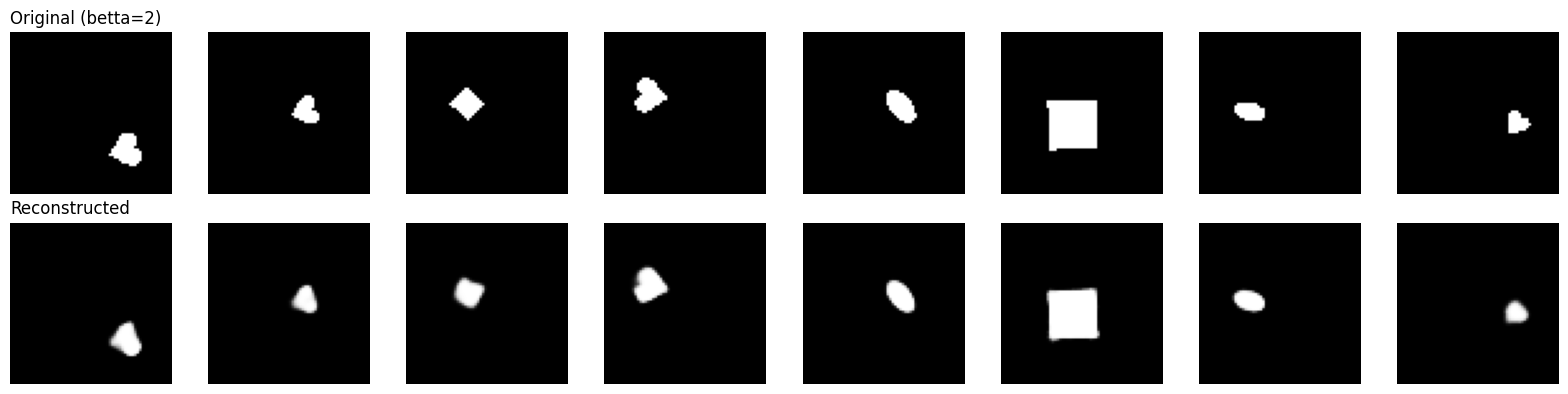

In [6]:

print("Visualizing 8 random reconstructions...")

model1_b.eval()

num_samples=8
indices=torch.randint(0,len(dataset),(num_samples,))
samples=torch.stack([dataset[i] for i in indices]).to(DEVICE)

with torch.no_grad():
    recon_samples,_,_=model1_b(samples)

samples_np=samples.cpu().numpy()
recon_samples_np=recon_samples.cpu().numpy()

plt.figure(figsize=(16,4))
for i in range(num_samples):
    ax=plt.subplot(2,num_samples,i +1)
    plt.imshow(samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title(f'Original (betta={b})',loc='left',fontsize=12)
        
    ax=plt.subplot(2,num_samples,i+1+num_samples)
    plt.imshow(recon_samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title("Reconstructed",loc='left',fontsize=12)

plt.tight_layout()
plt.show()

Starting training on cuda with H_DIM = 6...


Training Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 2/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 3/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 4/50:   0%|          | 0/5760 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch 48/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 49/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Epoch 50/50:   0%|          | 0/5760 [00:00<?, ?it/s]

Training finished.


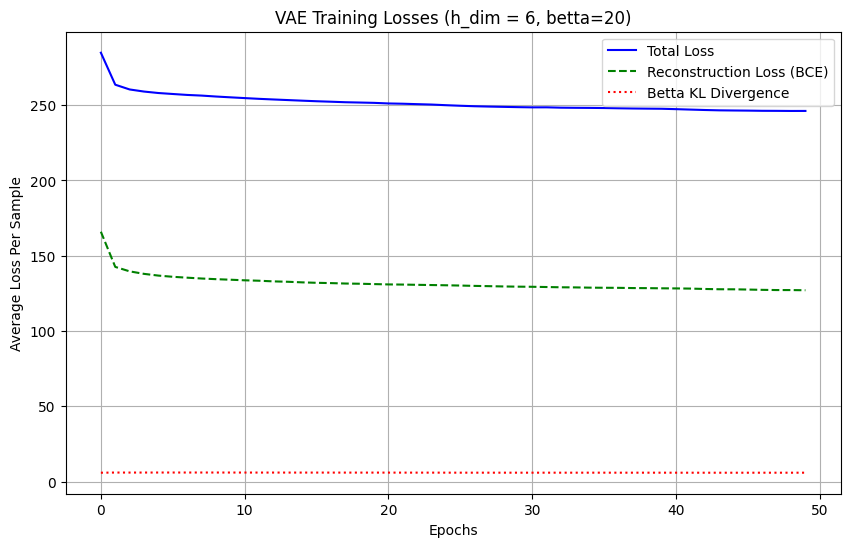

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from pathlib import Path
from tqdm.auto import tqdm

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS=50
LR=0.001
BATCH_SIZE=128
H_DIM=6 
IMG_DIM=(64,64)
b=20

class DspritesDataset(Dataset):
    def __init__(self,path):
        dataset=np.load(path,allow_pickle=True, encoding='latin1')
        self.imgs=torch.from_numpy(dataset['imgs']).float()
        
    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        return self.imgs[idx].unsqueeze(0)


class VAE(nn.Module):
    def __init__(self, h_dim=6):
        super(VAE, self).__init__()

        self.enc_conv1=nn.Conv2d(1,32,kernel_size=4,stride=2,padding=1) 
        self.enc_conv2=nn.Conv2d(32,64,kernel_size=4,stride=2,padding=1) 
        self.enc_conv3=nn.Conv2d(64,128,kernel_size=4,stride=2,padding=1)
        self.flatten=nn.Flatten()
        
        self.fc_mu=nn.Linear(8192,h_dim)
        self.fc_log_var=nn.Linear(8192,h_dim)
        
        self.dec_fc=nn.Linear(h_dim,8192)
        
        self.dec_convT1=nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1) 
        self.dec_convT2=nn.ConvTranspose2d(64,32,kernel_size=4,stride=2,padding=1) 
        self.dec_convT3=nn.ConvTranspose2d(32,1,kernel_size=4,stride=2,padding=1) 
        self.sigmoid=nn.Sigmoid()

    def encode(self,x):
        h=F.relu(self.enc_conv1(x))
        h=F.relu(self.enc_conv2(h))
        h=F.relu(self.enc_conv3(h))
        h=self.flatten(h)
        mu=self.fc_mu(h)
        log_var=self.fc_log_var(h)
        return mu,log_var

    def reparameterize(self, mu, log_var):
        std=torch.exp(0.5*log_var)
        eps=torch.randn_like(std)
        return mu+eps*std

    def decode(self,z):
        h=F.relu(self.dec_fc(z))
        h=h.view(-1,128,8,8) 
        h=F.relu(self.dec_convT1(h))
        h=F.relu(self.dec_convT2(h))
        x_recon=self.dec_convT3(h) 
        return self.sigmoid(x_recon)

    def forward(self,x):
        mu,log_var=self.encode(x)
        z=self.reparameterize(mu,log_var)
        recon_x=self.decode(z)
        return recon_x,mu,log_var

def vae_loss(recon_x,x,mu,log_var,b):

    BCE=F.binary_cross_entropy(recon_x,x,reduction='sum')
    
    KLD=-0.5*torch.sum(1+log_var-mu.pow(2)-log_var.exp())
    
    return BCE+b*KLD,BCE,KLD

model2_b=VAE(h_dim=H_DIM).to(DEVICE)
optimizer=Adam(model2_b.parameters(),lr=LR)

print(f"Starting training on {DEVICE} with H_DIM = {H_DIM}...")

all_total_losses=[]
all_bce_losses=[]
all_kld_losses=[]

model2_b.train()
epoch_pbar=tqdm(range(EPOCHS),desc="Training Epochs")

for epoch in epoch_pbar:
    epoch_total_loss=0
    epoch_bce_loss=0
    epoch_kld_loss=0
    
    batch_pbar=tqdm(loader,desc=f"Epoch {epoch+1}/{EPOCHS}",leave=False)
    
    for batch_idx,data in enumerate(batch_pbar):
        data=data.to(DEVICE)
        
        recon_batch,mu,log_var=model2_b(data)
        loss,bce,kld=vae_loss(recon_batch,data,mu,log_var,b)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_total_loss+=loss.item()
        epoch_bce_loss+=bce.item()
        epoch_kld_loss+=kld.item()
        
    avg_total=epoch_total_loss/len(dataset)
    avg_bce=epoch_bce_loss/len(dataset)
    avg_kld=epoch_kld_loss/len(dataset)
    
    all_total_losses.append(avg_total)
    all_bce_losses.append(avg_bce)
    all_kld_losses.append(avg_kld)
    
    epoch_pbar.set_postfix(TotalLoss=f"{avg_total:.4f}",BCE=f"{avg_bce:.4f}",KLD=f"{avg_kld:.4f}")

print("Training finished.")

plt.figure(figsize=(10,6))
plt.plot(all_total_losses,label='Total Loss',color='blue')
plt.plot(all_bce_losses,label='Reconstruction Loss (BCE)',color='green',linestyle='--')
plt.plot(all_kld_losses,label='Betta KL Divergence',color='red',linestyle=':')
plt.xlabel('Epochs')
plt.ylabel('Average Loss Per Sample')
plt.title(f'VAE Training Losses (h_dim = {H_DIM}, betta={b})')
plt.legend()
plt.grid(True)
plt.show()

Visualizing 8 random reconstructions...


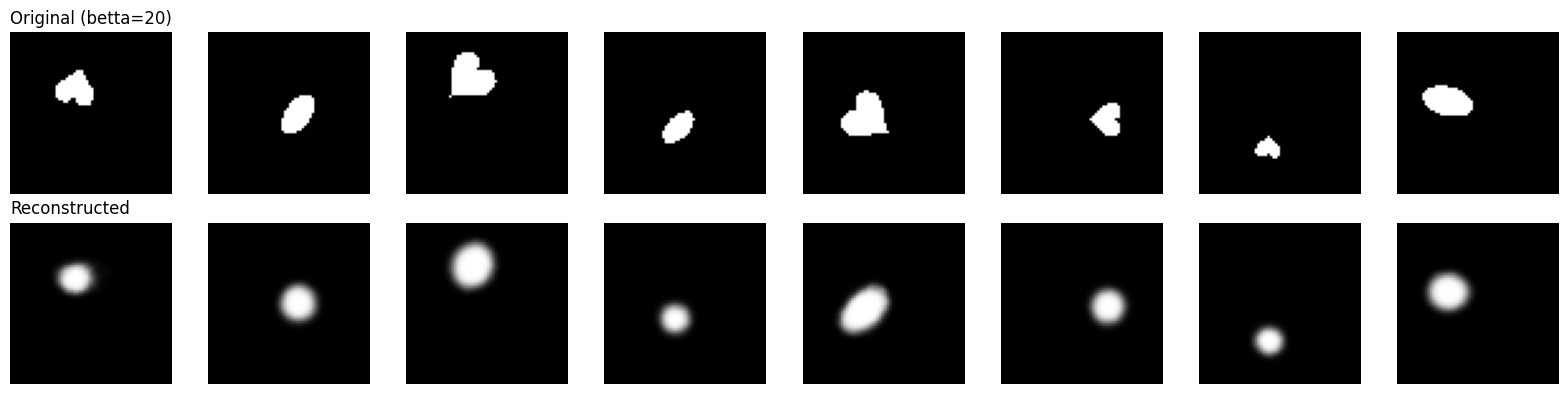

In [8]:

print("Visualizing 8 random reconstructions...")

model2_b.eval()

num_samples=8
indices=torch.randint(0,len(dataset),(num_samples,))
samples=torch.stack([dataset[i] for i in indices]).to(DEVICE)

with torch.no_grad():
    recon_samples,_,_=model2_b(samples)

samples_np=samples.cpu().numpy()
recon_samples_np=recon_samples.cpu().numpy()

plt.figure(figsize=(16,4))
for i in range(num_samples):
    ax=plt.subplot(2,num_samples,i +1)
    plt.imshow(samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title(f'Original (betta={b})',loc='left',fontsize=12)
        
    ax=plt.subplot(2,num_samples,i+1+num_samples)
    plt.imshow(recon_samples_np[i].reshape(64,64),cmap='gray')
    ax.axis('off')
    if i==0:
        ax.set_title("Reconstructed",loc='left',fontsize=12)

plt.tight_layout()
plt.show()

# MIG

In [13]:
import pandas as pd
from sklearn.metrics import mutual_info_score
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
from tqdm.auto import tqdm


DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATASET_PATH=Path("/kaggle/input/dsprites/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz")
BATCH_SIZE=512 


class DspritesEvalDataset(Dataset):
    def __init__(self, path):
        dataset=np.load(path,allow_pickle=True,encoding='latin1')
        self.imgs=dataset['imgs']
        self.gt_classes=dataset['latents_classes']
        
    def __len__(self):
        return len(self.imgs)

    def __getitem__(self,idx):
        img_tensor=torch.from_numpy(self.imgs[idx]).float().unsqueeze(0)
        gt_tensor=torch.from_numpy(self.gt_classes[idx]).long()
        return img_tensor,gt_tensor

print("Loading full dataset for evaluation...")
try:
    eval_dataset=DspritesEvalDataset(DATASET_PATH)
    eval_loader=DataLoader(eval_dataset,batch_size=BATCH_SIZE,shuffle=False)
    
    dsprites_npz=np.load(DATASET_PATH,allow_pickle=True,encoding='latin1')
    factor_names=list(dsprites_npz['metadata'][()]['latents_names'])
    gt_classes_all=dsprites_npz['latents_classes']

except Exception as e:
    print(f"An error occurred: {e}")

def entropy(labels):
    value,counts=np.unique(labels,return_counts=True)
    probs=counts/len(labels)
    return -np.sum(probs*np.log2(probs))

def calculate_mi_matrix(latent_means,gt_classes):
    num_latents=latent_means.shape[1]
    num_factors=gt_classes.shape[1]
    mi_matrix=np.zeros((num_latents,num_factors))
    
    discretized_latents=np.zeros_like(latent_means)
    for i in range(num_latents):
        bins=np.histogram(latent_means[:,i],bins=20)[1]
        if len(np.unique(bins))<len(bins):
            bins=20
        discretized_latents[:,i]=np.digitize(latent_means[:,i],bins[:-1])
    
    for i in range(num_latents):
        for k in range(num_factors):
            mi_matrix[i,k]=mutual_info_score(discretized_latents[:,i],gt_classes[:,k])
            
    return mi_matrix

def calculate_mig(mi_matrix,factor_entropies):
    num_factors=mi_matrix.shape[1]
    mig_scores={}
    
    for k in range(num_factors):
        if factor_entropies[k]==0:
            continue
            
        sorted_mi=np.sort(mi_matrix[:,k])[::-1]
        
        gap=sorted_mi[0]-sorted_mi[1]
        mig_scores[k]=gap/factor_entropies[k]
        
    return mig_scores

print("Calculating latent representations for all models (in batches)...")
model.eval()
model1_b.eval()
model2_b.eval()

all_mu_vae=[]
all_mu_beta_vae1=[]
all_mu_beta_vae2=[]

with torch.no_grad():
    for (imgs_batch,gts_batch) in tqdm(eval_loader,desc="Evaluating Batches"):
        imgs_batch=imgs_batch.to(DEVICE)
        
        mu_vae,_=model.encode(imgs_batch)
        mu_beta_vae1,_=model1_b.encode(imgs_batch)
        mu_beta_vae2,_=model2_b.encode(imgs_batch)
        
        all_mu_vae.append(mu_vae.cpu())
        all_mu_beta_vae1.append(mu_beta_vae1.cpu())
        all_mu_beta_vae2.append(mu_beta_vae2.cpu())

mu_vae_tensor=torch.cat(all_mu_vae, dim=0)
mu_beta_vae_tensor1=torch.cat(all_mu_beta_vae1,dim=0)
mu_beta_vae_tensor2=torch.cat(all_mu_beta_vae2,dim=0)

mu_vae_np=mu_vae_tensor.numpy()
mu_beta_vae_np1=mu_beta_vae_tensor1.numpy()
mu_beta_vae_np2=mu_beta_vae_tensor2.numpy()

factor_entropies=[entropy(gt_classes_all[:,k]) for k in range(gt_classes_all.shape[1])]

print("Calculating MIG scores...")

mi_matrix_vae=calculate_mi_matrix(mu_vae_np,gt_classes_all)
mig_scores_vae=calculate_mig(mi_matrix_vae,factor_entropies)

mi_matrix_beta_vae1=calculate_mi_matrix(mu_beta_vae_np1,gt_classes_all)
mig_scores_beta_vae1=calculate_mig(mi_matrix_beta_vae1,factor_entropies)

mi_matrix_beta_vae2=calculate_mi_matrix(mu_beta_vae_np2,gt_classes_all)
mig_scores_beta_vae2=calculate_mig(mi_matrix_beta_vae2,factor_entropies)

results=[]
valid_factor_names=[]

for k, name in enumerate(factor_names):
    if k in mig_scores_vae:
        valid_factor_names.append(name)
        results.append({
            "Factor": name,
            "VAE (beta=1)": mig_scores_vae[k],
            "Beta-VAE (beta=2)": mig_scores_beta_vae1[k],
            "Beta-VAE (beta=20)": mig_scores_beta_vae2[k]
        })

avg_vae=np.mean(list(mig_scores_vae.values()))
avg_beta_vae1=np.mean(list(mig_scores_beta_vae1.values()))
avg_beta_vae2=np.mean(list(mig_scores_beta_vae2.values()))

results.append({
    "Factor": "Average MIG",
    "VAE (beta=1)": avg_vae,
    "Beta-VAE (beta=2)": avg_beta_vae1,
    "Beta-VAE (beta=20)": avg_beta_vae2
})

df=pd.DataFrame(results).set_index('Factor')
print("\n--- Model MIG Score Comparison ---")
print(df.to_markdown(floatfmt=".4f"))

Loading full dataset for evaluation...
Calculating latent representations for all models (in batches)...


Evaluating Batches:   0%|          | 0/1440 [00:00<?, ?it/s]

Calculating MIG scores...

--- Model MIG Score Comparison ---
| Factor      |   VAE (beta=1) |   Beta-VAE (beta=2) |   Beta-VAE (beta=20) |
|:------------|---------------:|--------------------:|---------------------:|
| shape       |         0.0397 |              0.0228 |               0.0331 |
| scale       |         0.0657 |              0.0644 |               0.0738 |
| orientation |         0.0025 |              0.0009 |               0.0022 |
| posX        |         0.0198 |              0.0444 |               0.0276 |
| posY        |         0.0102 |              0.0860 |               0.0775 |
| Average MIG |         0.0276 |              0.0437 |               0.0428 |


Setting up DataLoader for batch-wise encoding...
Extracting latent space from the model (in batches)...


Encoding Batches:   0%|          | 0/720 [00:00<?, ?it/s]

Latent space dimensions: (737280, 6)
Running PCA to reduce dimensions to 2...
New dimensions after PCA: (737280, 2)
Variance explained by component 1: 29.06%
Variance explained by component 2: 28.05%
Total variance explained: 57.10%
Plotting graphs...


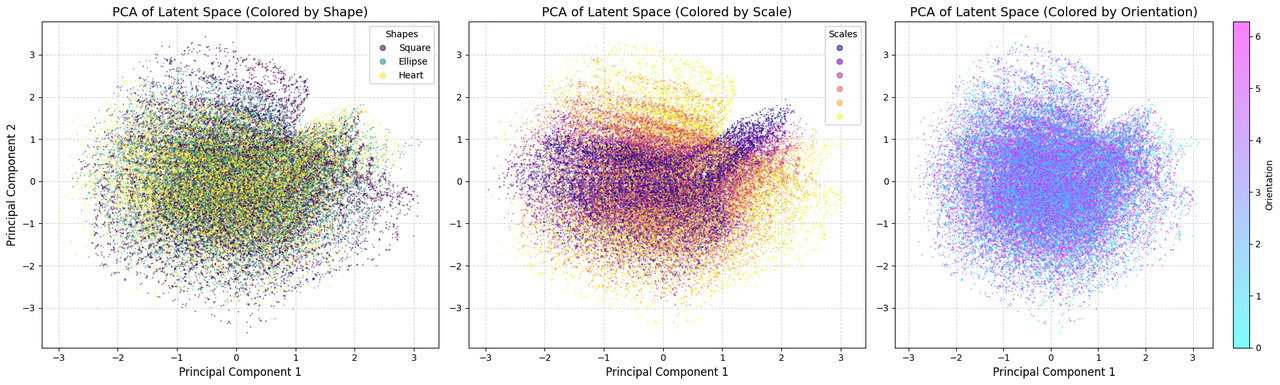

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.decomposition import PCA
from pathlib import Path
from tqdm.auto import tqdm


class DspritesDataset(Dataset):
    def __init__(self,path):
        dataset=np.load(path,allow_pickle=True,encoding='latin1')
        self.imgs=dataset['imgs']
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self,idx):
        return torch.from_numpy(self.imgs[idx]).float().unsqueeze(0)

print("Setting up DataLoader for batch-wise encoding...")
try:
    eval_dataset=DspritesDataset(DATASET_PATH)
    eval_loader=DataLoader(eval_dataset,batch_size=1024,shuffle=False)
except NameError:
    print("Error: DATASET_PATH is not defined. Please define it.")
except Exception as e:
    print(f"Error loading dataset: {e}")

print("Extracting latent space from the model (in batches)...")
model2_b.eval()
all_mu=[] 

with torch.no_grad():
    for data_batch in tqdm(eval_loader,desc="Encoding Batches"):
        data_batch=data_batch.to(DEVICE)
        
        mu_batch,_=model2_b.encode(data_batch)
        
        all_mu.append(mu_batch.cpu())

mu_latent_space_6d=torch.cat(all_mu,dim=0)

latent_space_6d=mu_latent_space_6d.numpy()
print(f"Latent space dimensions: {latent_space_6d.shape}")

print("Running PCA to reduce dimensions to 2...")
pca=PCA(n_components=2)
latent_space_2d=pca.fit_transform(latent_space_6d)
print(f"New dimensions after PCA: {latent_space_2d.shape}")

explained_variance=pca.explained_variance_ratio_
print(f"Variance explained by component 1: {explained_variance[0]*100:.2f}%")
print(f"Variance explained by component 2: {explained_variance[1]*100:.2f}%")
print(f"Total variance explained: {(explained_variance.sum())*100:.2f}%")

try:
    gt_values=dsprites_npz['latents_values']
    shape_labels=gt_values[:,factor_names.index('shape')]
    scale_labels=gt_values[:,factor_names.index('scale')]
    orientation_labels=gt_values[:,factor_names.index('orientation')]
    
    shape_map={1: 'Square', 2: 'Ellipse', 3: 'Heart'}
    shape_names=np.array([shape_map[label] for label in shape_labels])

except Exception as e:
    print(f"Error extracting factors: {e}")
    shape_labels=np.zeros(latent_space_2d.shape[0])
    scale_labels=np.zeros(latent_space_2d.shape[0])
    orientation_labels=np.zeros(latent_space_2d.shape[0])

print("Plotting graphs...")

plt.figure(figsize=(20,6))

ax1=plt.subplot(1,3,1)
sample_indices=np.random.choice(latent_space_2d.shape[0],50000,replace=False)

scatter1=ax1.scatter(
    latent_space_2d[sample_indices,0], 
    latent_space_2d[sample_indices,1], 
    c=shape_labels[sample_indices], 
    cmap='viridis',
    s=0.5,      
    alpha=0.5
)
ax1.set_title('PCA of Latent Space (Colored by Shape)',fontsize=14)
ax1.set_xlabel('Principal Component 1',fontsize=12)
ax1.set_ylabel('Principal Component 2',fontsize=12)
legend1=ax1.legend(
    handles=scatter1.legend_elements(num=[1,2,3])[0], 
    labels=['Square','Ellipse','Heart'], 
    title="Shapes"
)
ax1.add_artist(legend1)
ax1.grid(True,linestyle='--',alpha=0.5)

ax2=plt.subplot(1,3,2)
scatter2=ax2.scatter(
    latent_space_2d[sample_indices,0], 
    latent_space_2d[sample_indices,1], 
    c=scale_labels[sample_indices], 
    cmap='plasma',
    s=0.5, 
    alpha=0.5
)
ax2.set_title('PCA of Latent Space (Colored by Scale)',fontsize=14)
ax2.set_xlabel('Principal Component 1',fontsize=12)
legend2=ax2.legend(handles=scatter2.legend_elements(num=6)[0],title="Scales")
ax2.add_artist(legend2)
ax2.grid(True,linestyle='--',alpha=0.5)

ax3=plt.subplot(1,3,3)
scatter3=ax3.scatter(
    latent_space_2d[sample_indices,0], 
    latent_space_2d[sample_indices,1], 
    c=orientation_labels[sample_indices], 
    cmap='cool',
    s=0.5, 
    alpha=0.5
)
ax3.set_title('PCA of Latent Space (Colored by Orientation)',fontsize=14)
ax3.set_xlabel('Principal Component 1',fontsize=12)
cbar=plt.colorbar(scatter3,ax=ax3)
cbar.set_label('Orientation')
ax3.grid(True,linestyle='--',alpha=0.5)

plt.tight_layout()
plt.show()

